<div style="border:solid Chocolate 2px; padding: 40px">

<b>Привет  Андрей  !</b>

Меня зовут Дмитрий Михаленко, я буду ревьюером твоего проекта. Если ты не против, то предлагаю построить наше общение на "ты" ;) Если удобнее на "вы", то нет проблем, только скажи об этом. 

Ниже в работе ты найдешь мои комментарии - **пожалуйста, не перемещай, не изменяй и не удаляй их**.
    
Для наглядности я буду использовать цветовую разметку:
<font color='green'>зеленого</font>, <font color='gold'>желтого</font> и <font color='red'>красного</font> цветов. Сейчас объясню, что они значат:

<br/>

<div class="alert alert-success">
<h2> Комментарий ревьюера <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Решение на этом шаге является полностью правильным.
</div>

<br/>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Решение на этом шаге может стать еще лучше, если внести небольшие коррективы.
Но настаивать я не буду.
</div>


<br/>
<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера <a class="tocSkip"></h2>

    
<b>На доработку🤔:</b>
Для правильного решения задачи на этом шаге необходимо внести правки. Напоминаю, что проект не может быть принят, без их отработки.
</div>

Для продуктивной работы прошу: **если ты что-то меняешь в проекте или отвечаешь на мои комментарии — пиши об этом**
Мне будет легче отследить изменения, если ты тоже выделишь свои комментарии:
    
<div class="alert alert-info"> <b>Комментарий студента:</b> Например, вот так.</div>

Всё это поможет выполнить повторную проверку твоего проекта оперативнее. 
        
Увидев у тебя ошибку, в первый раз я лишь укажу на ее наличие и дам тебе возможность самостоятельно найти и исправить ее. На реальной работе твой начальник будет поступать так же, а я пытаюсь подготовить тебя именно к работе аналитиком. Но если ты пока не справишься с такой задачей - при следующей проверке я дам более точную подсказку.

# Проект спринта 22. Разработка A/B-тестирования и анализ результатов

## Цель проекта
Анализ результатов A/B-тестирования после внедрения рекомендательной системы, имеющей целью увеличение времени, проводимого пользователем в приложении.

## Описание данных

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. Путь к файлу: `/datasets/sessions_project_history.csv`.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. Путь к файлу: `/datasets/sessions_project_test_part.csv`.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02. Путь к файлу: `/datasets/sessions_project_test.csv`.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).


## Задачи
1. Рассчитать параметры теста;
2. Оценить корректность проведения теста;
3. Проанализировать результаты эксперимента.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b>Содержательное введение на основе данных шаблона. По нему любому пользователю сразу будет понятен контекст работы

### Импорт необходимых библиотек и методов

In [1]:
%pip install -q statsmodels pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from math import ceil

# Импорт инструментов для расчёта мощности теста и эффекта
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest

# Импорт pandas для работы с таблицами
import pandas as pd

# Библиотеки для построения графиков
import seaborn as sns
import matplotlib.pyplot as plt

# Для форматирования в HTML
from IPython.display import display, HTML, Markdown

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных

In [3]:
BASE_URL = "https://code.s3.yandex.net/"

def load_dataset(file_name, **kwargs):
    try:
        if os.path.exists(file_name):
            return pd.read_csv(file_name, **kwargs)
        else:
            return pd.read_csv(BASE_URL + file_name, **kwargs)
    except:
        print("Ошибка загрузки датасета")
        raise

def show_dataset_info(df, title):
    display(HTML(f"<h2>{title}</h2>"))
    df.info()
    display(df.head())
    display(HTML(f"<h3>Количество полных дубликатов: {df.duplicated().sum()}</h3>"))

sessions_history = load_dataset("datasets/sessions_project_history.csv")
show_dataset_info(sessions_history, "sessions_project_history")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   user_id            435924 non-null  object
 1   session_id         435924 non-null  object
 2   session_date       435924 non-null  object
 3   session_start_ts   435924 non-null  object
 4   install_date       435924 non-null  object
 5   session_number     435924 non-null  int64 
 6   registration_flag  435924 non-null  int64 
 7   page_counter       435924 non-null  int64 
 8   region             435924 non-null  object
 9   device             435924 non-null  object
dtypes: int64(3), object(7)
memory usage: 33.3+ MB


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b>При знакомсве с исходными данными полезно еще использовать `describe`. А также делать небольшой вывод

- Даты загружены как строки, требуется преобразование типов.
- Пропуски и полные дубликаты в таблице отсутствуют.

In [4]:
sessions_history['session_date'] = pd.to_datetime(sessions_history['session_date'])
sessions_history['session_start_ts'] = pd.to_datetime(sessions_history['session_start_ts'])
sessions_history['install_date'] = pd.to_datetime(sessions_history['install_date'])

sessions_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   user_id            435924 non-null  object        
 1   session_id         435924 non-null  object        
 2   session_date       435924 non-null  datetime64[ns]
 3   session_start_ts   435924 non-null  datetime64[ns]
 4   install_date       435924 non-null  datetime64[ns]
 5   session_number     435924 non-null  int64         
 6   registration_flag  435924 non-null  int64         
 7   page_counter       435924 non-null  int64         
 8   region             435924 non-null  object        
 9   device             435924 non-null  object        
dtypes: datetime64[ns](3), int64(3), object(4)
memory usage: 33.3+ MB


#### 1.2. Знакомство с данными
- Рассчитаем количество уникальных сессий по пользователям.
- Выберем пользователя с максимальным количеством сессий.

In [5]:
sessions_count = (sessions_history
                  .groupby('user_id')['session_id']
                  .nunique()
                  .sort_values(ascending=False)
                  .reset_index())

max_sessions_user_id = sessions_count.loc[0, 'user_id']
display(HTML("<h3>Пользователи с максимальным количеством сессий</h3>"))
display(sessions_count.head())

display(HTML("<h3>История по пользователю с максимальным количеством сессий</h3>"))
max_user_history = (sessions_history[sessions_history['user_id'] == max_sessions_user_id]
                    .sort_values(by='session_start_ts'))

display(max_user_history)

,user_id,session_id
0,10E0DEFC1ABDBBE0,10
1,6A73CB5566BB494D,10
2,8A60431A825D035B,9
3,D11541BAC141FB94,9
4,5BCFE7C4DCC148E9,9


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1<a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Решение верное, покажу альтернативный вариант 
        
```python
# Код ревьюера:
user_with_max_sessions = sessions_history.groupby('user_id')['session_id'].nunique().idxmax()
sessions_history[sessions_history['user_id'] == user_with_max_sessions]       
        
        
```        

- Максимальное количество сессий одного пользователя - 10.
- Можно считать, что регион и тип устройства для одного пользователя не меняется от сессии к сессии.

#### 1.3. Анализ числа регистраций
- Исследуем, как менялось число регистраций в приложении за время его существования. Пользователь считается зарегистрированным только в день совершения регистрации. Для простоты будем считать, что у пользователя в течение дня бывает одна сессия максимум и статус регистрации в течение одного дня не может измениться.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> У нас в проекте есть ограничение - одна запись в день, но несмотря на это лучше брать именно `nunique` при рассчетах как ты. 

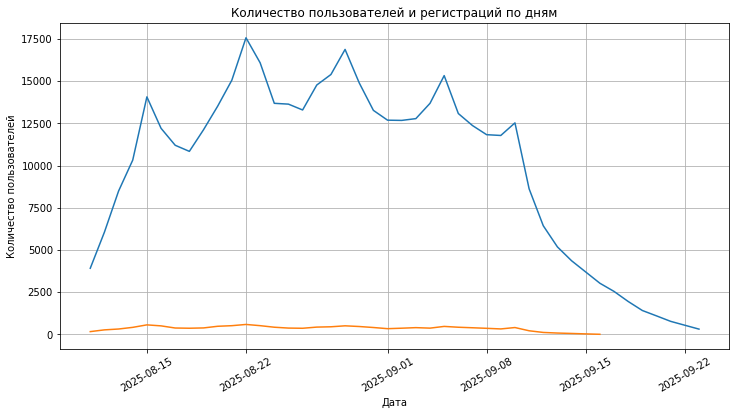

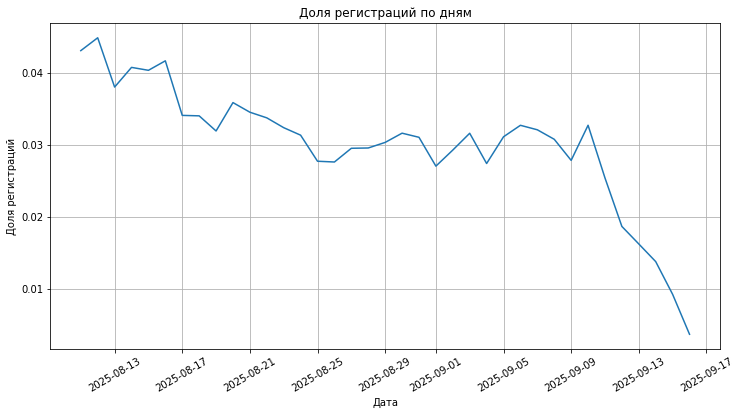

In [6]:
total_count = sessions_history.groupby('session_date')['user_id'].nunique()
registrations_count = (sessions_history[sessions_history['registration_flag'] == 1]
                 .groupby('user_id')['session_date']
                 .min()
                 .reset_index()
                 .groupby(by='session_date')
                 .size())
registrations_ratio = registrations_count / total_count

def draw_graph(x, labels, xlabel, ylabel, title, figsize=(12, 6), rotation=30):
    plt.figure(figsize=figsize)
    for g, label in zip(x, labels):
        plt.plot(g.index, g.values, label=label)
    plt.grid()
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=rotation)
    plt.title(title)
    plt.show()

draw_graph([total_count, registrations_count],
          ["Количество пользователей", "Количество регистраций"],
          "Дата", "Количество пользователей",
          "Количество пользователей и регистраций по дням")

draw_graph([registrations_ratio],
          ["Доля регистраций"],
          "Дата", "Доля регистраций",
          "Доля регистраций по дням")

- На графиках заметен периоды резкого роста количества пользователей в начале и его падения в конце временного интервала. Вероятно, это периоды с неполными данными (постепенное накопление и остановка сбора данных). 
- Доля новых регистраций постепенно падает в течение периода стабильных данных.
- Локальные пики количества клиентов наблюдаются с недельным интервалом по пятницам, всплеска количества регистраций в эти дни не наблюдается.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Молодец, что не упускаешь промежуточные интерпретации

#### 1.4. Анализ числа просмотренных страниц
- Построим график распределения первых сессий по количеству просмотренных страниц.

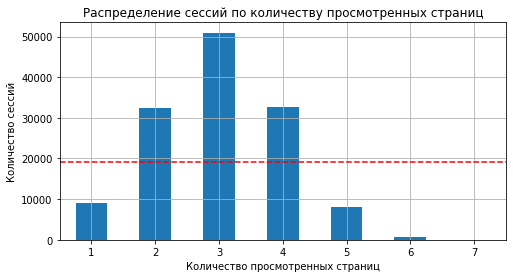

In [7]:
first_sessions = (sessions_history
                .sort_values('session_start_ts')
                .groupby('user_id')
                .first()
                .reset_index())
pages_view_count = first_sessions['page_counter'].reset_index()
def draw_barplot(series, 
                 title, 
                 xlabel, 
                 ylabel, 
                 rot=0, 
                 vertical=True, 
                 mean=None):
    series.plot(
        title=title,
        kind='bar' if vertical else 'barh',
        figsize=(8, 4) if vertical else (12, 4),
        xlabel=xlabel if vertical else ylabel,
        ylabel=ylabel if vertical else xlabel,
        grid=True,
        rot=rot)
    
    if mean != None:
        if vertical:
            plt.axhline(mean, color='red', linestyle='--')
        else:
            plt.axvline(mean, color='red', linestyle='--')
    plt.show()

pages_count_distribution = pages_view_count['page_counter'].value_counts().sort_index()

draw_barplot(pages_count_distribution,
             "Распределение сессий по количеству просмотренных страниц",
             "Количество просмотренных страниц",
             "Количество сессий",
             mean=pages_count_distribution.mean())

- Распределение близко к нормальному со средним значением около 3. 
- Наибольшее количество пользователей просмотрело 3 страницы, максимальное количество - 7 страниц. Это мало для приложений, представляющих видеоконтент. 

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Тут  наша целевая метрика сессии с 4 и более страницами и полезно описать  насколько именно такие сессии популярны в сравнении с другими.  

#### 1.5. Доля пользователей, просмотревших более четырёх страниц
- Сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.
- Добавим столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше.
- Построим график среднего значения доли сессий с просмотром 4 и более страниц от всех первых сессий пользователей.

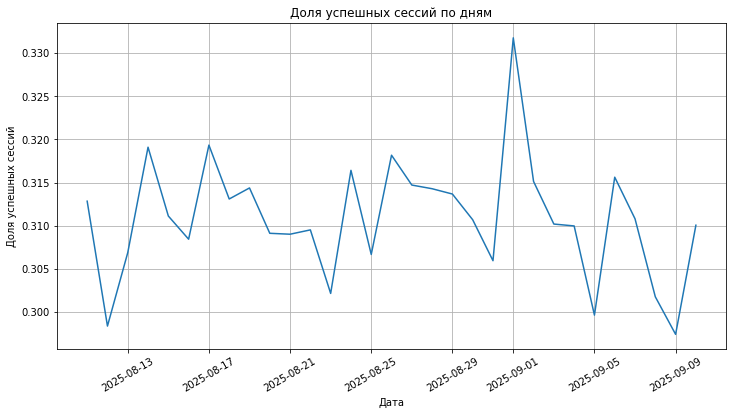

In [8]:
sessions_history['good_session'] = sessions_history['page_counter'] >= 4
first_sessions['good_session'] = first_sessions['page_counter'] >= 4
good_sessions_ratio = first_sessions.groupby('session_date')['good_session'].mean()
draw_graph([good_sessions_ratio],
          ["Доля успешных сессий"],
          "Дата", "Доля успешных сессий",
          "Доля успешных сессий по дням")

- Доля успешных сессий за период наблюдений колеблется, но в среднем остается около 3.1%. 
- Роста средней доли успешных сессий не наблюдается.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> среднее значение доли успешных сессий проанализировано корректно

### 2. Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Определиться с целевой метрикой.
- Рассчитать необходимый размер выборки.
- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста.

#### 2.1. Расчёт размера выборки
Рассчитаем необходимый размер выборки со следующими параметрами:
- Уровень значимости — 0.05.
- Вероятность ошибки второго рода — 0.2.
- Минимальный детектируемый эффект, или MDE, — 3%.

In [9]:
# Задайте параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода
power = 1 - beta  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = 0.03  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=1
)

print(f"Необходимый размер выборки: {ceil(sample_size)}")

Необходимый размер выборки: 3762


#### 2.2. Расчёт длительности A/B-теста

- Рассчитаем длительность теста, исходя из количества уникальных пользователей в день и необходимого размера выборки.

In [10]:
# Среднее количество пользователей приложения в день по историческим данным
avg_daily_users = sessions_history.groupby('session_date')['user_id'].nunique().mean()

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil(sample_size / avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровене трафика в {avg_daily_users:.2f} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровене трафика в 9907.36 пользователей в день составит 1 дней


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b>Тут тоже все корректно и по коду и по максимально понятному пользователю выводу  результата

### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей
- Проверим распределение пользователей по группам.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3130 entries, 0 to 3129
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            3130 non-null   object
 1   session_id         3130 non-null   object
 2   session_date       3130 non-null   object
 3   session_start_ts   3130 non-null   object
 4   install_date       3130 non-null   object
 5   session_number     3130 non-null   int64 
 6   registration_flag  3130 non-null   int64 
 7   page_counter       3130 non-null   int64 
 8   region             3130 non-null   object
 9   device             3130 non-null   object
 10  test_group         3130 non-null   object
dtypes: int64(3), object(8)
memory usage: 269.1+ KB


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,3404844B53442747,B4901323BD537E45,2025-10-14,2025-10-14 19:28:49,2025-10-14,1,0,3,CIS,Android,B
1,3A2BF4D364E62D89,216FC619308F8788,2025-10-14,2025-10-14 21:11:04,2025-10-14,1,0,3,MENA,iPhone,A
2,79CDAE11E32B1597,EDFCE4AC1A504074,2025-10-14,2025-10-14 21:44:03,2025-10-14,1,0,3,CIS,iPhone,A
3,D6AF8D78297A931F,CF0AC0EEDE92C690,2025-10-14,2025-10-14 19:07:55,2025-10-14,1,0,4,CIS,PC,A
4,37E0CE723AE568E0,2E6ED45E8C86C4E9,2025-10-14,2025-10-14 15:39:44,2025-10-14,1,0,3,CIS,Mac,B


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3130 entries, 0 to 3129
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            3130 non-null   object        
 1   session_id         3130 non-null   object        
 2   session_date       3130 non-null   datetime64[ns]
 3   session_start_ts   3130 non-null   datetime64[ns]
 4   install_date       3130 non-null   datetime64[ns]
 5   session_number     3130 non-null   int64         
 6   registration_flag  3130 non-null   int64         
 7   page_counter       3130 non-null   int64         
 8   region             3130 non-null   object        
 9   device             3130 non-null   object        
 10  test_group         3130 non-null   object        
dtypes: datetime64[ns](3), int64(3), object(5)
memory usage: 269.1+ KB


session_date
2025-10-14    2943
Name: user_id, dtype: int64

test_group
A    1477
B    1466
Name: user_id, dtype: int64

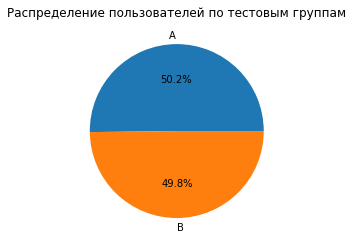

Разница в количестве пользователей между группами A и B составляет 0.74%


In [11]:
sessions_test_part = load_dataset("datasets/sessions_project_test_part.csv")
show_dataset_info(sessions_test_part, "sessions_project_test_part")

sessions_test_part['session_date'] = pd.to_datetime(sessions_test_part['session_date'])
sessions_test_part['session_start_ts'] = pd.to_datetime(sessions_test_part['session_start_ts'])
sessions_test_part['install_date'] = pd.to_datetime(sessions_test_part['install_date'])

sessions_test_part.info()

display(HTML("<h3>Количество пользователей в датасете по датам</h3>"))
display(sessions_test_part.groupby('session_date')['user_id'].nunique())

display(HTML("<h3>Количество пользователей в тестовых группах</h3>"))
display(sessions_test_part.groupby('test_group')['user_id'].nunique())

users_distribution = sessions_test_part.groupby('test_group')['user_id'].nunique()
users_distribution.plot(
    kind='pie',
    autopct='%1.1f%%',
    ylabel='',
    title='Распределение пользователей по тестовым группам'
)
plt.show()

pct_diff = abs(users_distribution['A'] - users_distribution['B']) / users_distribution['A'] * 100
print(f"Разница в количестве пользователей между группами A и B составляет {pct_diff:.2f}%")

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> По выполненным расчетам и графику видим, что группы практически одинакового размера. Это важно всегда проверять перед проведением статистического теста

#### 3.2. Проверка пересечений пользователей
- Проверим, что в группах A и B нет общих пользователей.

In [12]:
number_of_common_users = (sessions_test_part
                          .groupby('user_id')['test_group']
                          .nunique()
                          .reset_index()
                          .query('test_group > 1')
                          .shape[0])

if(number_of_common_users > 0):
    display(HTML(f"<h3>В тестовых группах есть {number_of_common_users} пользователей, которые попали в обе группы. "
                 f"Необходимо исключить их из анализа.</h3>"))
else:
    display(HTML("<h3>В тестовых группах нет пользователей, которые попали в обе группы.</h3>"))

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Проверка пересечений пользователей также проведена верно! Важный момент для любого независимого АB теста

#### 3.3. Равномерность разделения пользователей по устройствам
Проверим, что пользователи равномерно распределены по типам устройств.

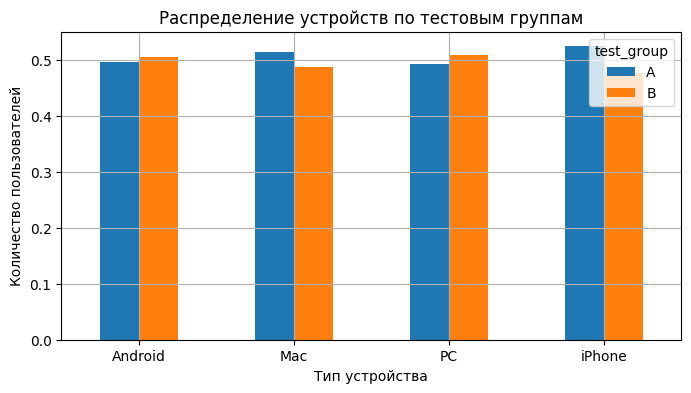

In [13]:
device_by_group_ratio = (
    sessions_test_part.groupby(['device', 'test_group'])['user_id']
                      .nunique()
                      .groupby(level=0)
                      .transform(lambda x: x / x.sum())
                      .unstack()
)

draw_barplot(device_by_group_ratio,
             "Распределение устройств по тестовым группам",
             "Тип устройства",
             "Количество пользователей")

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Можно дополнительно вместе с графиками показать сводную талицу с абсолютными и относительными значниями. Все для этого у тебя есть, а пользователи смогут удобнее видеть и возможно применить в дальнейшем конкретные значения по категориям

- Доли пользователей по каждому типу устройств в обеих тестовых группах примерно равны.

#### 3.4. Равномерность распределения пользователей по регионам
Проверим, что пользователи равномерно распределены по регионам.

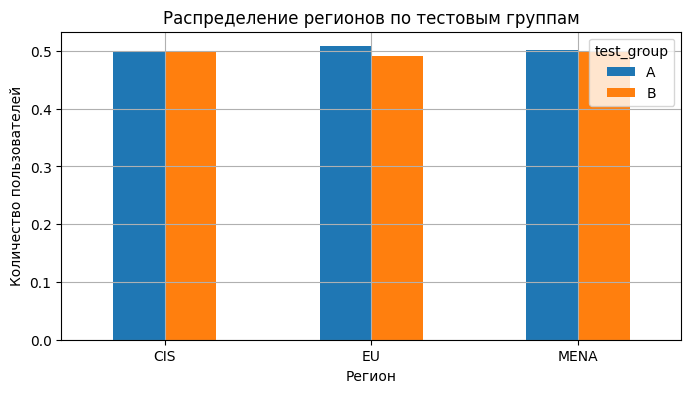

In [14]:
device_by_region_ratio = (
    sessions_test_part.groupby(['region', 'test_group'])['user_id']
                      .nunique()
                      .groupby(level=0)
                      .transform(lambda x: x / x.sum())
                      .unstack()
)

draw_barplot(device_by_region_ratio,
             "Распределение регионов по тестовым группам",
             "Регион",
             "Количество пользователей")

- Доли пользователей по каждому региону в обеих тестовых группах примерно равны.

#### 3.5. Вывод после проверки A/B-теста
- Количество пользователей в группах A и B в данных за один день теста различается незначительно (0.74%)
- Группы A и B не содержат общих пользователей - выборки независимы.
- Пользователи в разных регионах и с разными типами устройств распределены по группам примерно поровну.

A/B тест проходит корректно, однако данных за один день недостаточно для статистически значимого результата (требуется 3762 пользователя, накоплены данные по 2943 пользователям).

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b>  молодец, что обобщил итоги анализа предпосылок  проведения эксперемента

### 4. Проверка результатов A/B-теста

#### 4.1. Получение результатов теста и подсчёт основной метрики

- Загрузим CSV-файл с историческими данными о сессиях пользователей `sessions_project_test.csv`.
- Создадим дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если просмотрено меньше.

In [15]:
sessions_test = load_dataset("datasets/sessions_project_test.csv")
show_dataset_info(sessions_test, "sessions_project_test")

sessions_test['session_date'] = pd.to_datetime(sessions_test['session_date'])
sessions_test['session_start_ts'] = pd.to_datetime(sessions_test['session_start_ts'])
sessions_test['install_date'] = pd.to_datetime(sessions_test['install_date'])

sessions_test.info()

sessions_test['good_session'] = sessions_test['page_counter'] >= 4

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100005 entries, 0 to 100004
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   user_id            100005 non-null  object
 1   session_id         100005 non-null  object
 2   session_date       100005 non-null  object
 3   session_start_ts   100005 non-null  object
 4   install_date       100005 non-null  object
 5   session_number     100005 non-null  int64 
 6   registration_flag  100005 non-null  int64 
 7   page_counter       100005 non-null  int64 
 8   region             100005 non-null  object
 9   device             100005 non-null  object
 10  test_group         100005 non-null  object
dtypes: int64(3), object(8)
memory usage: 8.4+ MB


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100005 entries, 0 to 100004
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   user_id            100005 non-null  object        
 1   session_id         100005 non-null  object        
 2   session_date       100005 non-null  datetime64[ns]
 3   session_start_ts   100005 non-null  datetime64[ns]
 4   install_date       100005 non-null  datetime64[ns]
 5   session_number     100005 non-null  int64         
 6   registration_flag  100005 non-null  int64         
 7   page_counter       100005 non-null  int64         
 8   region             100005 non-null  object        
 9   device             100005 non-null  object        
 10  test_group         100005 non-null  object        
dtypes: datetime64[ns](3), int64(3), object(5)
memory usage: 8.4+ MB


#### 4.2 Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик
По мнению разработчиков рекомендательной системы, основной результат её внедрения должен состоять в увеличении времени, проводимом пользователями в приложении. Следовательно, в качестве целевой метрики можно взять долю "хороших" сессий, т.е. сессий с просмотром 4 и более страниц.
- Нулевая гипотеза ($H_0$): доля "хороших" сессий осталась неизменной.
- Альтернативная гипотеза ($H_1$): доля "хороших" сессий увеличилась.

- В качестве прокси-метрики можно рассмотреть количество пользователей с "хорошими" сессиями. Увеличение этого количества будет значить, что алгоритм подбирает интересный контент для широкого круга пользователей.
- Барьерной метрикой может служить среднее количество просмотренных страниц в первых сессиях. Раньше оно имело среднее значение 3, после внедрения рекомендательной системы оно не должно уменьшиться.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b>исходные данные для теста описаны грамотно, молодец, что не забываешь про данный момент

#### 4.3. Сравнение доли успешных сессий
- Рассчитаем долю успешных сессий для выборок A и B.

In [16]:
good_sessions_history_ratio = first_sessions['good_session'].mean()

first_sessions_test = (sessions_test
                       .sort_values('session_start_ts')
                       .groupby('user_id')
                       .first()
                       .reset_index())

good_sessions_test_ratio = first_sessions_test['good_session'].mean()

print(f"Средняя доля успешных сессий в исторических данных: {good_sessions_history_ratio.mean():.4f}")
print(f"Средняя доля успешных сессий в тестовых данных: {good_sessions_test_ratio.mean():.4f}")
print(f"""Процентная разница в доле успешных сессий между историческими и тестовыми данными: \
{(good_sessions_history_ratio.mean() - good_sessions_test_ratio.mean()) / good_sessions_history_ratio.mean() * 100:.2f}%""")

Средняя доля успешных сессий в исторических данных: 0.3106
Средняя доля успешных сессий в тестовых данных: 0.3149
Процентная разница в доле успешных сессий между историческими и тестовыми данными: -1.38%


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b>Рассчеты верны и очень хорошо, что округление не грубое

#### 4.4. Насколько статистически значимо изменение ключевой метрики
- Проверим статистическую значимость полученных результатов, используя Z-тест для пропорций.

In [17]:
n_a, n_b = first_sessions.shape[0], first_sessions_test.shape[0]
m_a, m_b = first_sessions['good_session'].sum(), first_sessions_test['good_session'].sum()

print(f"Количество пользователей в исторических данных: {n_a}")
print(f"Количество пользователей в тестовых данных: {n_b}")

alpha = 0.05
stat_ztest, p_value_ztest = proportions_ztest(
    [m_a, m_b],
    [n_a, n_b],
    alternative='smaller' # так как H_1: p_a < p_b
)

if p_value_ztest > alpha:
    print(f'pvalue={p_value_ztest} > {alpha}')
    print('Нулевая гипотеза не опровергнута!')
else:
    print(f'pvalue={p_value_ztest} < {alpha}')
    print('Альтернативная гипотеза подтверждается!')

Количество пользователей в исторических данных: 134039
Количество пользователей в тестовых данных: 30579
pvalue=0.07187182139335112 > 0.05
Нулевая гипотеза не опровергнута!


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b>С проведением теста все абсолютно верно, хвалю!

#### 4.5. Вывод по результатам A/B-эксперимента
- Для проведения A/B-тестирования результатов внедрения рекомендательной системы были предоставлены исторические данные за период с 2025-08-15 по 2025-09-23.
- Данные не содержат пропусков и дубликатов.
- Доля новых регистраций постепенно падает в течение периода стабильных данных.
- Локальные пики количества клиентов наблюдаются с недельным интервалом по пятницам, всплеска количества регистраций в эти дни не наблюдается.
- Распределение количества просмотренных в первых сессиях страниц близко к нормальному со средним значением около 3. 
- Наибольшее количество пользователей просмотрело 3 страницы, максимальное количество - 7 страниц. Это недостаточно для приложений, представляющих видеоконтент. 
- Доля "успешных" сессий (с просмотром 4 и более страниц) за период наблюдений колеблется, но в среднем остается около 3.1%. 
- Роста средней доли "успешных" сессий не наблюдается.
- За целевую метрику была взята доля "успешных" первых сессий пользователей за день.
- Нулевая гипотеза ($H_0$): доля "хороших" сессий осталась неизменной.
- Альтернативная гипотеза ($H_1$): доля "хороших" сессий увеличилась.
- Были использовны следующие параметры проверки A/B-теста:
    - Уровень значимости — 0.05.
    - Вероятность ошибки второго рода — 0.2.
    - Минимальный детектируемый эффект (MDE) — 3%.
- Размер выборки, необходимой для статистически значимого теста составил 3762 первых сессий (пользователей).
- Длительность теста, исходя из среднего количества пользователей 9907.36 в день, составила 1 день.
- В результате анализа данных, поступивших за первый день теста, было установлено, что:
    - Количество пользователей в группах A и B в данных за один день теста различается незначительно (0.74%)
    - Группы A и B не содержат общих пользователей - выборки независимы.
    - Пользователи в разных регионах и с разными типами устройств распределены по группам примерно поровну.
    - A/B тест проходит корректно, однако данных, накопленных за один день теста, недостаточно для статистически значимого результата (требуется 3762 пользователя, накоплены данные по 2943 пользователям).
- По результатам A/B-теста, продолжавшегося с 2025-10-14 по 2025-11-02, в тесте были учтены данные по сессиям 30579 пользователей, средняя доля "успешных" первых сессий увеличилась на 1.38%.
- Была проведена проверка статистической значимости полученного результата с использованием z-теста пропорций. Значение p-value составило 0.0719, что больше уровня значимости 0.05. На текущих данных нет оснований отклонить нулевую гипотезу.
- На основании проведенного теста можно утверждать, что увеличение среднего количества "успешных" сессий является случайным, и внедрение нового алгоритма рекомендаций не привело к устойчивому росту количества просмотров.
- Внедрение нового алгоритма рекомендаций не является целесообразным, так как оно не способствует привлечению пользователей.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b>  Андрей, отличный итоговый вывод в котором есть и предпосылки и результаты и главное - рекомендации для бизнеса, хвалю!
    
Итоговые выводы - важная часть работы и в твоих будующих реальных проектах советую уделять ей особое внимание. Бывают ситуации, когда у руководства нет времени вникать в весь проект и оценка твоих действий будет проводиться именно по ним.        

<div style="border:solid Chocolate 2px; padding: 40px">
    
**Общий вывод по проекту ревьювера**:
     Андрей, спасибо за качественный проект! Приложено много усилий, чтобы довести его до конца, проделана огромная работа, и это видно невооруженным глазом, ты молодец! 
    
Все сделано в соответствии с ТЗ и поэтому, чтобы не задерживать тебя на пути обучения я приму его сразу, если останутся вопросы по моим дополнениям - ты всегда можешь обратиться ко мне через куратора, буду рад помочь)
    
**Отмечу положительные моменты**:
    
    1. Все разложено по полочкам, всегда понятен ход твоих мыслей, приятно смотреть.
    
    2. Уместные и хорошо оформленные визуализации.      
    
    3. Грамотное написание элементов кода
    
    
    
    
**Поздравляю тебя, еще одна аналитическая работа попадает в твое портфолио. Желаю успешного и интересного продолжения учебы!**
    
    